<img src="https://www.pucsp.br/sites/default/files/download/brasao-PUCSP-assinatura-principal-RGB.png" style="float:right;" width="150px">

# Ciências da Computação [》](https://www.pucsp.br/graduacao/ciencia-da-computacao)

## Inteligência Artificial

IA ML (Machine Learning, Aprendizagem de Máquina)

**Objetivo deste exercício é explorar os modelos de Random Forest (Árvore Aleatória) com Scikit-Learn em Python, sobre os dados de algum conjunto do Vega Dataset**

Inteligência Artificial - ML com Scikit-learn

**Dupla**

| | Nome | Usuário no GitHub |
| --- | --- | --- |
| Integrante 1 | Daniel Teles de Oliveira | DanielTelesdeOlivera |
| Integrante 2 | João Victor Torres Soares | JTSoares |

# TODO
Verificar se você sobreviveria ao terrível naufrágio do Titanic com este modelo



1.   Escolher um dataset do vegas dataset
2.   Experimentar estatística descritiva para preencher alguma coluna com valores ausentes
2.   Experimentar regressão e classificação
3.   Elaborar visualizações
5.   Realizar a limpeza dos dados
6.   Treinar e verificar a acuracia do modelo






In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from vega_datasets import data
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [73]:
print(data.list_datasets())

['7zip', 'airports', 'annual-precip', 'anscombe', 'barley', 'birdstrikes', 'budget', 'budgets', 'burtin', 'cars', 'climate', 'co2-concentration', 'countries', 'crimea', 'disasters', 'driving', 'earthquakes', 'ffox', 'flare', 'flare-dependencies', 'flights-10k', 'flights-200k', 'flights-20k', 'flights-2k', 'flights-3m', 'flights-5k', 'flights-airport', 'gapminder', 'gapminder-health-income', 'gimp', 'github', 'graticule', 'income', 'iowa-electricity', 'iris', 'jobs', 'la-riots', 'londonBoroughs', 'londonCentroids', 'londonTubeLines', 'lookup_groups', 'lookup_people', 'miserables', 'monarchs', 'movies', 'normal-2d', 'obesity', 'ohlc', 'points', 'population', 'population_engineers_hurricanes', 'seattle-temps', 'seattle-weather', 'sf-temps', 'sp500', 'stocks', 'udistrict', 'unemployment', 'unemployment-across-industries', 'uniform-2d', 'us-10m', 'us-employment', 'us-state-capitals', 'volcano', 'weather', 'weball26', 'wheat', 'windvectors', 'world-110m', 'zipcodes']


# Escolha do conjunto de dados countries - countries
O conjunto de dados reúne informações sobre diferentes países, incluindo indicadores de expectativa de vida e taxa de fertilidade, associados aos respectivos anos de observação.

In [74]:
df = data.countries()

# Descrição do conjunto
Nesta etapa, realiza-se uma análise da estrutura e da volumetria do conjunto de dados, verificando a quantidade de registros e colunas, as características das variáveis numéricas e a visualização das primeiras amostras. Essa análise inicial permite compreender a organização dos dados e obter uma visão geral do conjunto antes das etapas seguintes do processamento.

In [75]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 630 entries, 0 to 629
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   _comment       1 non-null      object 
 1   year           630 non-null    int64  
 2   fertility      630 non-null    float64
 3   life_expect    630 non-null    float64
 4   n_fertility    567 non-null    float64
 5   n_life_expect  567 non-null    float64
 6   country        630 non-null    object 
 7   p_fertility    567 non-null    float64
 8   p_life_expect  567 non-null    float64
dtypes: float64(6), int64(1), object(2)
memory usage: 44.4+ KB


In [76]:
total_registros = len(df)
print(total_registros)

630


In [77]:
df.describe()

,year,fertility,life_expect,n_fertility,n_life_expect,p_fertility,p_life_expect
count,630.000000,630.000000,630.000000,567.000000,567.000000,567.000000,567.000000
mean,1977.500000,3.731504,65.473222,3.592239,66.342941,3.871930,64.777197
std,14.372818,1.938239,10.631994,1.895985,10.217575,1.949564,10.551816
min,1955.000000,0.940000,23.599000,0.940000,23.599000,1.080000,23.599000
25%,1965.000000,2.072500,59.357250,1.993500,60.180000,2.241000,58.340060
50%,1977.500000,3.106600,68.740000,2.942000,69.610000,3.313000,67.849000
75%,1990.000000,5.361500,73.450750,5.000000,73.825000,5.599800,72.755000
max,2000.000000,8.500000,82.000000,8.500000,82.000000,8.500000,80.690000


In [78]:
df.head()

,_comment,year,fertility,life_expect,n_fertility,n_life_expect,country,p_fertility,p_life_expect
0,Data courtesy of Gapminder.org,1955,7.7,30.332,7.7,31.997,Afghanistan,NaN,NaN
1,NaN,1960,7.7,31.997,7.7,34.020,Afghanistan,7.7,30.332
2,NaN,1965,7.7,34.020,7.7,36.088,Afghanistan,7.7,31.997
3,NaN,1970,7.7,36.088,7.7,38.438,Afghanistan,7.7,34.020
4,NaN,1975,7.7,38.438,7.8,39.854,Afghanistan,7.7,36.088


# Visualizações de tendências e de comparações com gráficos e tabelas
Nesta etapa, realiza-se uma análise exploratória dos dados por meio de gráficos e tabelas, com o objetivo de identificar tendências temporais na expectativa de vida e na taxa de fertilidade média, comparar os países com os maiores e menores valores desses indicadores e investigar a relação entre eles por meio de um gráfico de dispersão.

## Evolução da Expectativa de Vida ao Longo dos Anos

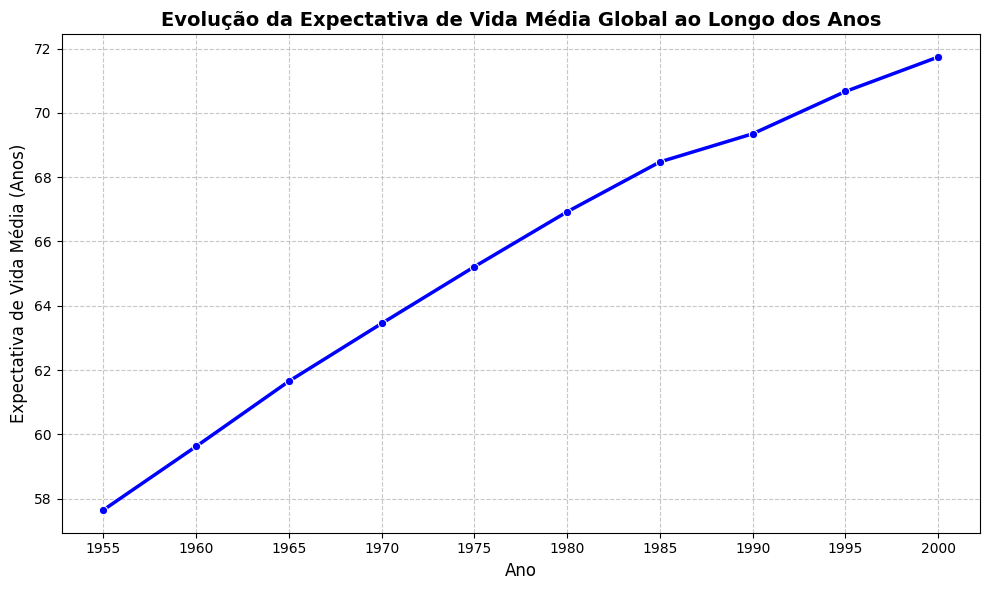

In [79]:
# Agrupando os dados por ano para calcular a média da expectativa de vida
evolucao_vida = df.groupby('year')['life_expect'].mean().reset_index()

plt.figure(figsize=(10, 6))
sns.lineplot(data=evolucao_vida, x='year', y='life_expect', marker='o', color='b', linewidth=2.5)

plt.title('Evolução da Expectativa de Vida Média Global ao Longo dos Anos', fontsize=14, fontweight='bold')
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Expectativa de Vida Média (Anos)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(evolucao_vida['year'].unique())

plt.tight_layout()
plt.show()

## Evolução da Fertilidade ao Longo dos Anos

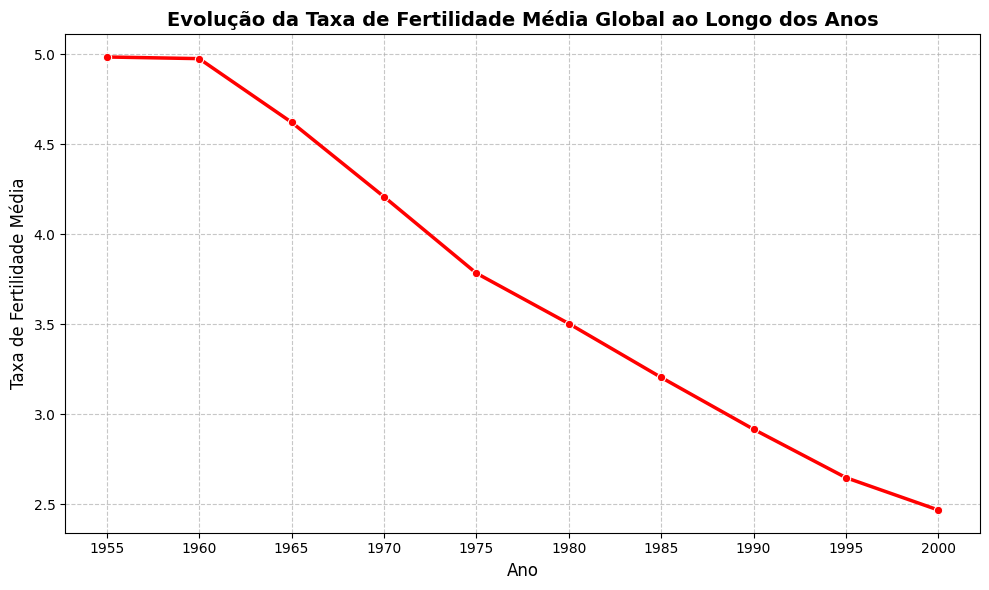

In [80]:
# Agrupando os dados por ano para calcular a média da fertilidade
evolucao_fertilidade = df.groupby('year')['fertility'].mean().reset_index()

plt.figure(figsize=(10, 6))
sns.lineplot(data=evolucao_fertilidade, x='year', y='fertility', marker='o', color='r', linewidth=2.5)

plt.title('Evolução da Taxa de Fertilidade Média Global ao Longo dos Anos', fontsize=14, fontweight='bold')
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Taxa de Fertilidade Média', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(evolucao_fertilidade['year'].unique())

plt.tight_layout()
plt.show()

### Tabela de Expectativa de Vida por País

In [81]:
# Selecionando o ano mais recente disponível para ter os dados atuais de cada país
ano_mais_recente = df['year'].max()
df_recente = df[df['year'] == ano_mais_recente]

tabela_expectativa = df_recente[['country', 'life_expect']].sort_values(by='life_expect', ascending=False).reset_index(drop=True)

tabela_expectativa.columns = ['País', 'Expectativa de Vida (Anos)']

display(tabela_expectativa)

,País,Expectativa de Vida (Anos)
0,Japan,82.000
1,Hong Kong,81.495
2,Switzerland,80.620
3,Iceland,80.500
4,Australia,80.370
...,...,...
58,South Africa,53.365
59,Kenya,50.992
60,Nigeria,46.608
61,Rwanda,43.413


## Comparação dos 5 Países com Maior Expectativa de Vida

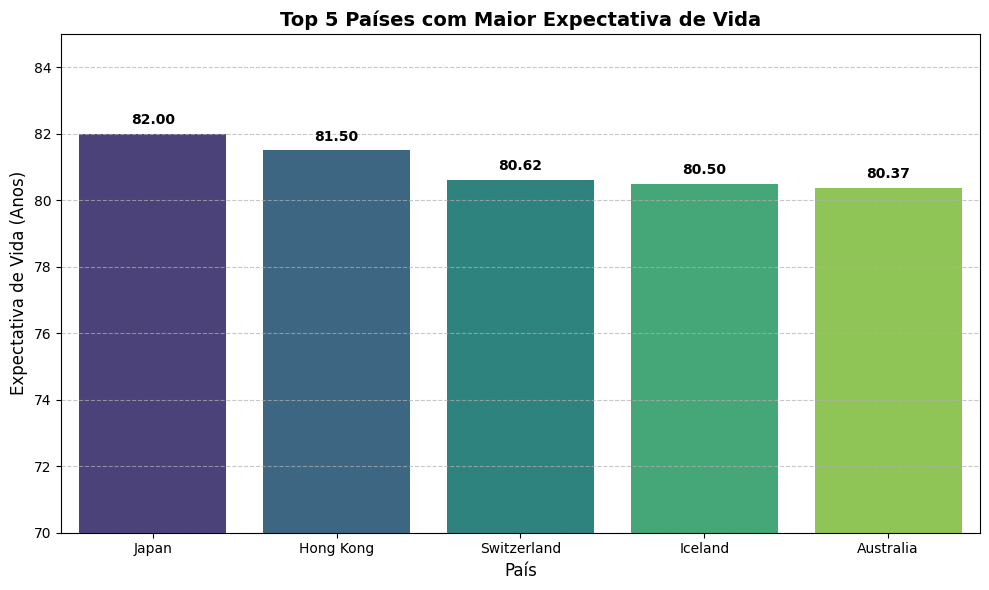

In [82]:
top_5_expectativa = tabela_expectativa.head(5)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_5_expectativa,
    x='País',
    y='Expectativa de Vida (Anos)',
    hue='País',
    palette='viridis',
    legend=False
)

plt.title('Top 5 Países com Maior Expectativa de Vida', fontsize=14, fontweight='bold')
plt.xlabel('País', fontsize=12)
plt.ylabel('Expectativa de Vida (Anos)', fontsize=12)
plt.ylim(70, 85) #
plt.grid(axis='y', linestyle='--', alpha=0.7)

for index, row in top_5_expectativa.iterrows():
    plt.text(
        x=index,
        y=row['Expectativa de Vida (Anos)'] + 0.2,
        s=f"{row['Expectativa de Vida (Anos)']:.2f}",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

### Tabela de Taxa de Fertilidade por País

In [83]:
ano_mais_recente = df['year'].max()
df_recente = df[df['year'] == ano_mais_recente]

tabela_fertilidade = df_recente[['country', 'fertility']].sort_values(by='fertility', ascending=False).reset_index(drop=True)

tabela_fertilidade.columns = ['País', 'Taxa de Fertilidade']

display(tabela_fertilidade)

,País,Taxa de Fertilidade
0,Afghanistan,7.4792
1,Rwanda,6.0100
2,Nigeria,5.8450
3,Kenya,5.0000
4,Iraq,4.8580
...,...,...
58,Italy,1.2860
59,Greece,1.2770
60,Poland,1.2510
61,North Korea,1.2420


## Comparação dos 5 Países com Maior Taxa de Fertilidade

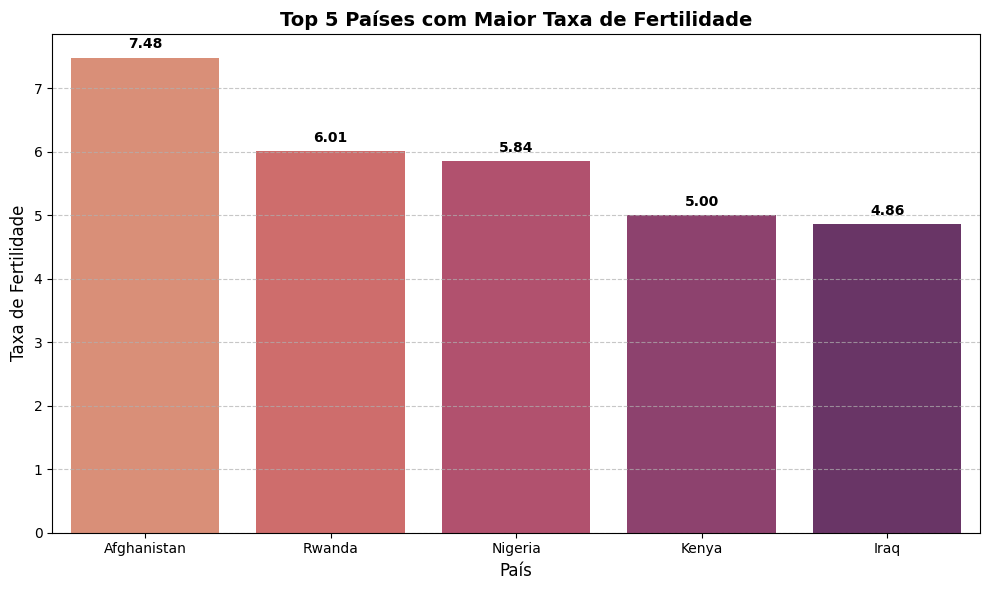

In [84]:
# Selecionando os 5 países com maior taxa de fertilidade
top_5_fertilidade = tabela_fertilidade.head(5)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_5_fertilidade,
    x='País',
    y='Taxa de Fertilidade',
    hue='País',
    palette='flare',
    legend=False
)

plt.title('Top 5 Países com Maior Taxa de Fertilidade', fontsize=14, fontweight='bold')
plt.xlabel('País', fontsize=12)
plt.ylabel('Taxa de Fertilidade', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for index, row in top_5_fertilidade.iterrows():
    plt.text(
        x=index,
        y=row['Taxa de Fertilidade'] + 0.1,
        s=f"{row['Taxa de Fertilidade']:.2f}",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

## Relação entre Fertilidade e Expectativa de Vida

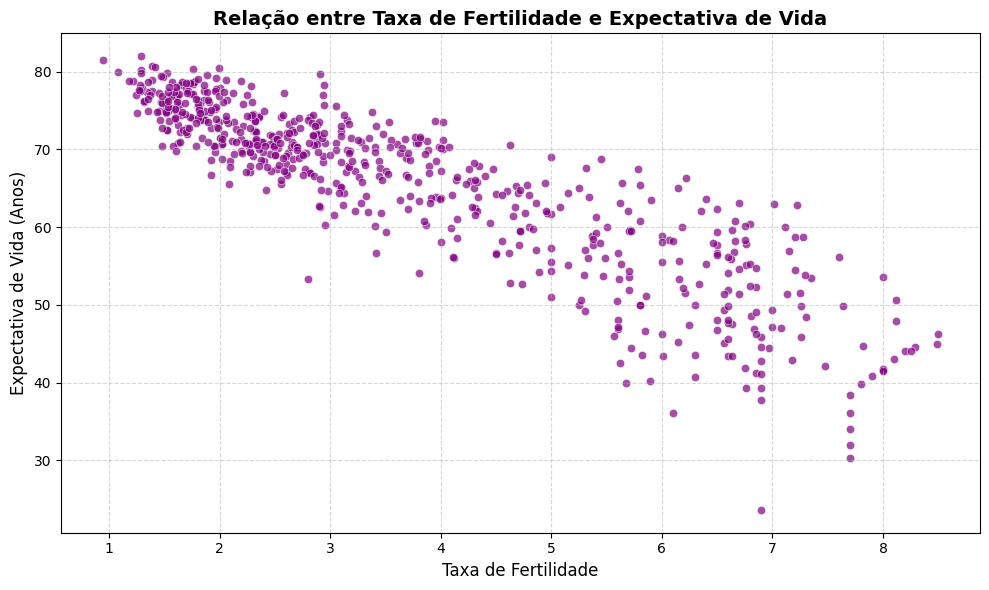

In [85]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='fertility', y='life_expect', alpha=0.7, color='purple')

plt.title('Relação entre Taxa de Fertilidade e Expectativa de Vida', fontsize=14, fontweight='bold')
plt.xlabel('Taxa de Fertilidade', fontsize=12)
plt.ylabel('Expectativa de Vida (Anos)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Análise de Valores ausentes
Nesta etapa, realiza-se uma investigação da presença e da distribuição de valores ausentes no conjunto de dados, com o objetivo de identificar possíveis perdas nas informações e avaliar seus impactos na qualidade dos dados e no desempenho dos modelos preditivos.

In [86]:
df.isnull().sum()

,0
_comment,629
year,0
fertility,0
life_expect,0
n_fertility,63
n_life_expect,63
country,0
p_fertility,63
p_life_expect,63


<Axes: >

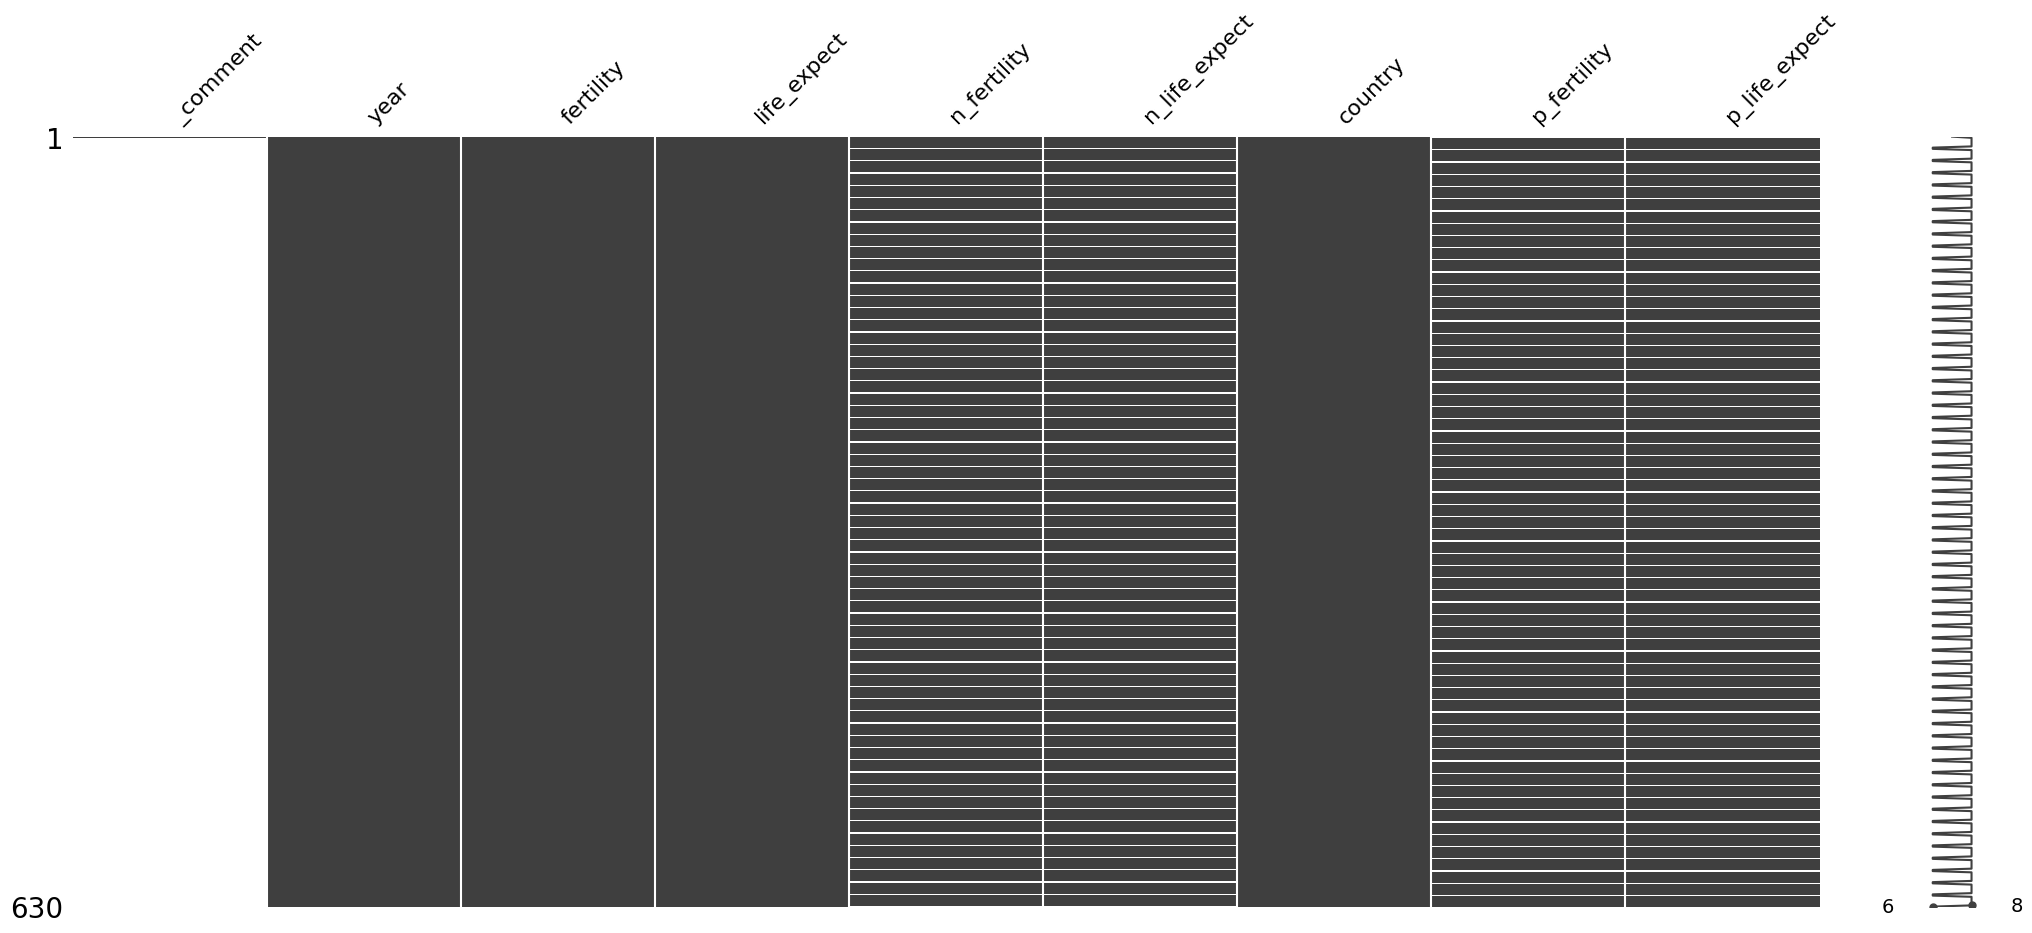

In [87]:
msno.matrix(df)

<Axes: >

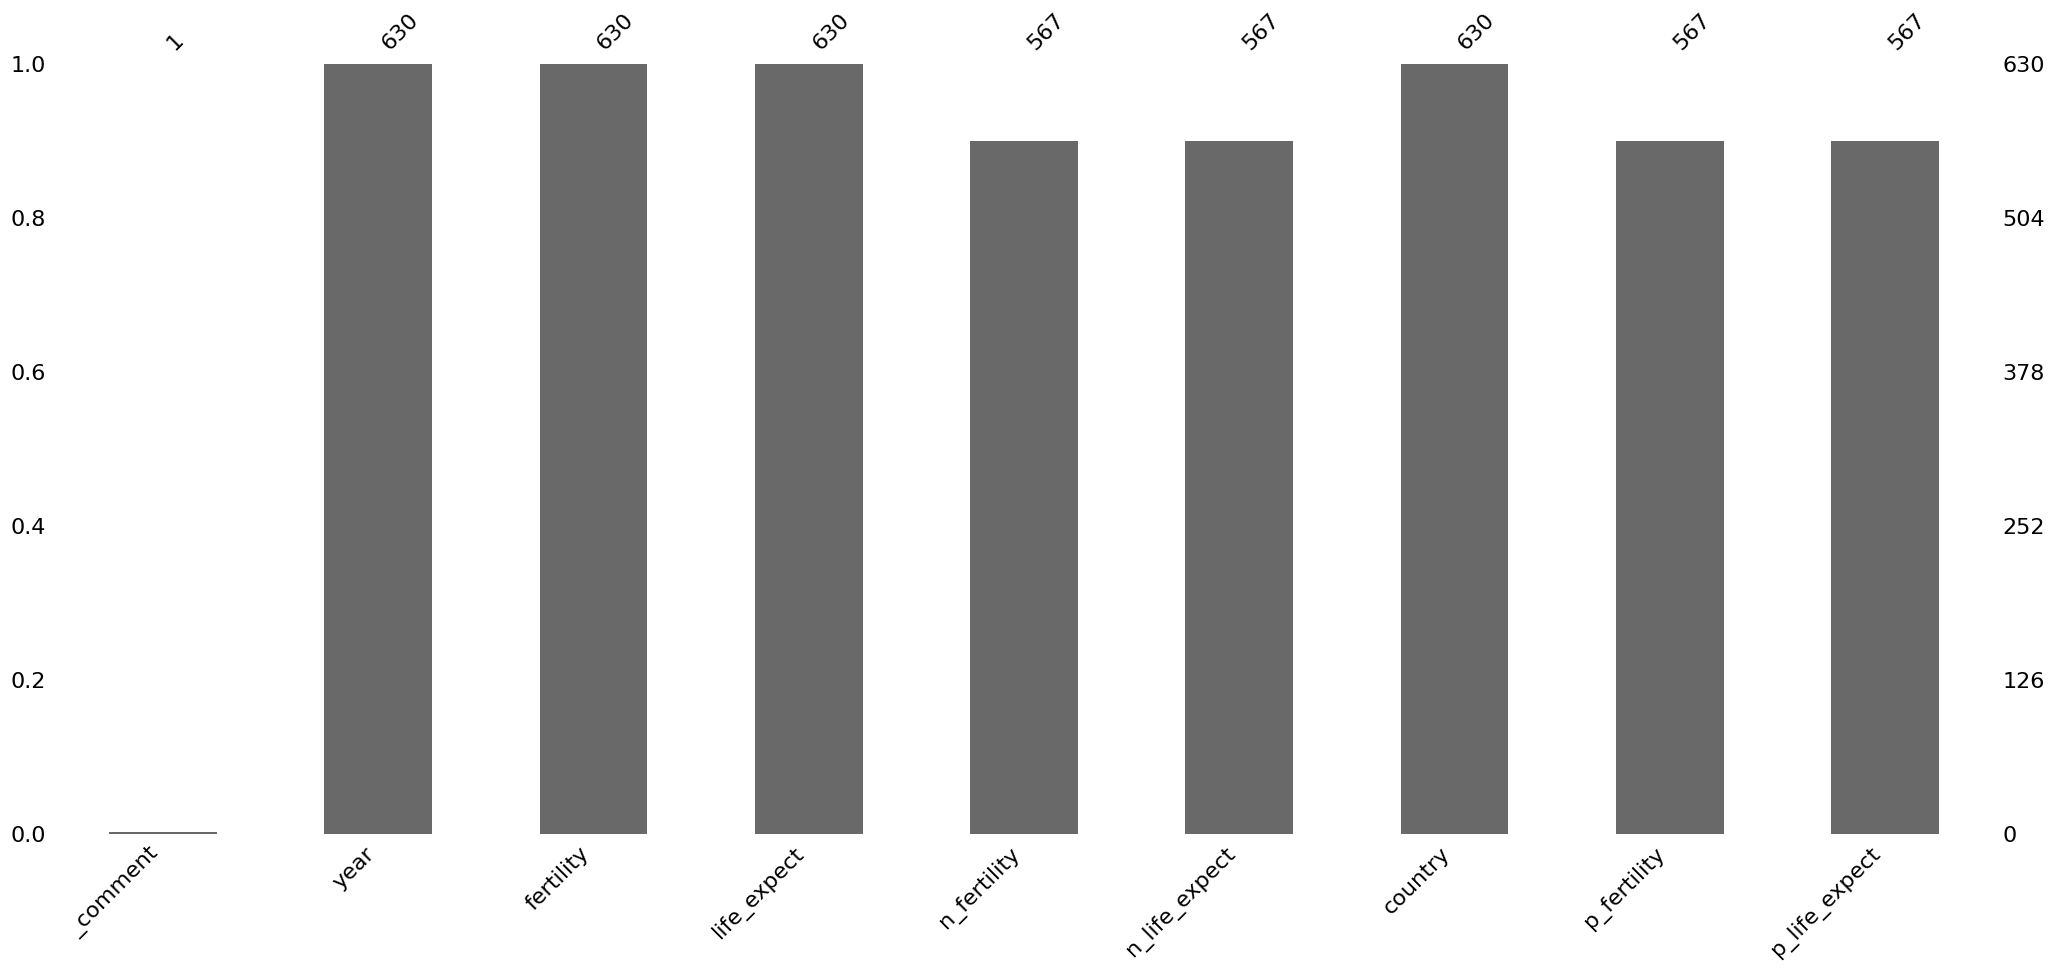

In [88]:
msno.bar(df)

# Verificação de Outliers

Nesta etapa, investiga-se a presença de valores extremos nas variáveis numéricas do conjunto de dados, com o objetivo de identificar possíveis inconsistências e observações atípicas que possam influenciar o treinamento e o desempenho dos modelos preditivos. Essa análise permite avaliar a necessidade de manter, corrigir ou tratar esses valores, considerando o contexto e a distribuição de cada variável.

In [89]:
colunas_numericas = df.select_dtypes(include=[np.number]).columns.drop('year', errors='ignore')

outliers_dict = {}

print("=== Detecção de Outliers usando o Intervalo Interquartil (IQR) ===\n")

for col in colunas_numericas:
    # Remove valores nulos temporariamente para o cálculo dos quartis
    col_data = df[col].dropna()

    if len(col_data) == 0:
        continue

    Q1 = col_data.quantile(0.25)
    Q3 = col_data.quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = col_data[(col_data < limite_inferior) | (col_data > limite_superior)]

    outliers_dict[col] = outliers.tolist()

    print(f"Variável: {col}")
    print(f"  Q1: {Q1:.3f} | Q3: {Q3:.3f} | IQR: {IQR:.3f}")
    print(f"  Limites: [{limite_inferior:.3f}, {limite_superior:.3f}]")
    print(f"  Quantidade de Outliers: {len(outliers)}")
    if len(outliers) > 0:
        print(f"  Valores Outliers: {outliers.tolist()[:10]}... (mostrando até 10 valores)" if len(outliers) > 10 else f"  Valores Outliers: {outliers.tolist()}")
    print("-" * 50)

=== Detecção de Outliers usando o Intervalo Interquartil (IQR) ===

Variável: fertility
  Q1: 2.072 | Q3: 5.362 | IQR: 3.289
  Limites: [-2.861, 10.295]
  Quantidade de Outliers: 0
--------------------------------------------------
Variável: life_expect
  Q1: 59.357 | Q3: 73.451 | IQR: 14.093
  Limites: [38.217, 94.591]
  Quantidade de Outliers: 7
  Valores Outliers: [30.332, 31.997, 34.02, 36.088, 37.802, 23.599, 36.087]
--------------------------------------------------
Variável: n_fertility
  Q1: 1.994 | Q3: 5.000 | IQR: 3.006
  Limites: [-2.516, 9.510]
  Quantidade de Outliers: 0
--------------------------------------------------
Variável: n_life_expect
  Q1: 60.180 | Q3: 73.825 | IQR: 13.645
  Limites: [39.713, 94.292]
  Quantidade de Outliers: 7
  Valores Outliers: [31.997, 34.02, 36.088, 38.438, 39.36, 23.599, 36.087]
--------------------------------------------------
Variável: p_fertility
  Q1: 2.241 | Q3: 5.600 | IQR: 3.359
  Limites: [-2.797, 10.638]
  Quantidade de Outliers:

# Justificativa de Preservação dos Outliers Demográficos
Foram identificados outliers principalmente nas colunas de expectativa de vida, com valores excepcionalmente baixos.

Porém, essess valores representam fenômenos reais e históricos, não sendo sendo, portanto, algum erro de digitação ou falha de medição.

Se esses valores forem removidos, os modelos aprenderiam apenas cenários ideais ou moderados. Ao manter esses dados, permitimos que o modelo compreenda e preveja cenários de crise e comportamento demográfico sob forte estresse social.


Portanto, esses valores atípicos são fundamentais para garantir a representatividade da desigualdade socioeconômica global na análise.

# Correlação entre variáveis
Nesta etapa, analisam-se as correlações entre as variáveis do conjunto de dados, com o objetivo de identificar a intensidade e a direção das relações entre elas, bem como avaliar quais apresentam maior associação com a variável-alvo e podem contribuir para o desempenho do modelo preditivo.

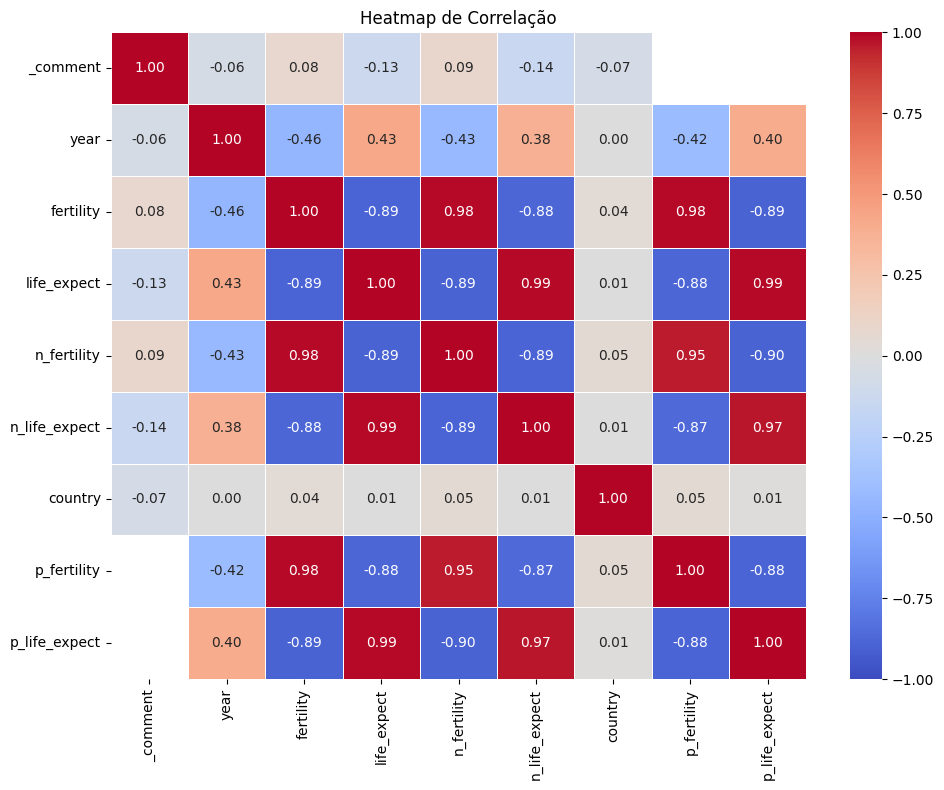

In [90]:
df_encoded = df.copy()

# Conversão de colunas categóricas/objeto em numéricas
for col in df_encoded.select_dtypes(include=['object']).columns:
    df_encoded[col] = df_encoded[col].astype('category').cat.codes

# Cálculo das correlações
corr_matrix = df_encoded.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1, vmax=1
)

plt.title('Heatmap de Correlação')
plt.tight_layout()
plt.show()

# Objetivos da regressão e classificação

O objetivo da regressão é estimar os valores históricos da expectativa de vida com base nas variáveis disponíveis no conjunto de dados. Já a classificação busca prever se a expectativa de vida aumentará em relação ao valor atual, categorizando o resultado em duas classes: aumento (1) ou ausência de aumento (0).

# Criação de uma nova coluna para realizar classificação e checagem de balancemanto
Nesta etapa, cria-se uma nova variável binária denominada expectativa_vai_aumentar, que indica se a expectativa de vida aumentará em relação ao valor atual. A variável recebe o valor 1 quando n_life_expect é maior que life_expect, indicando um aumento, e 0 caso contrário. Essa transformação permite estruturar o problema como uma tarefa de classificação supervisionada, na qual o modelo busca prever a ocorrência de um aumento na expectativa de vida.

In [91]:
df['expectativa_vai_aumentar'] = (df['n_life_expect'] > df['life_expect']).astype(int)

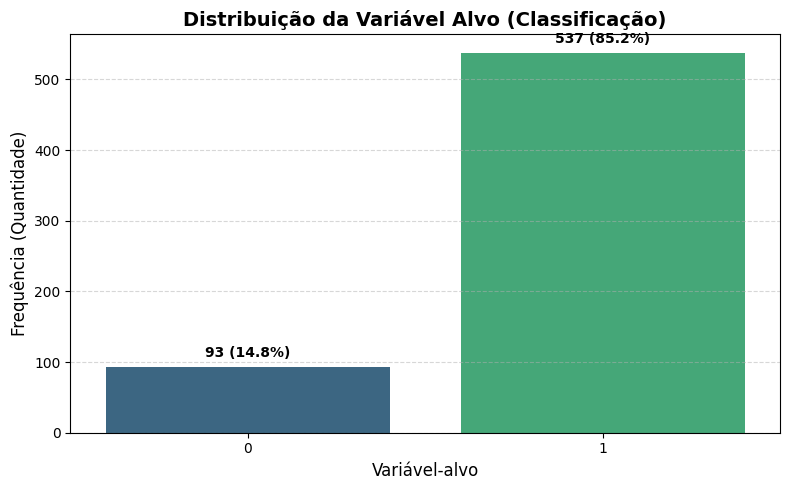

In [92]:
# Visualização da distribuição da variável alvo de classificação
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x='expectativa_vai_aumentar',
    hue='expectativa_vai_aumentar',
    palette='viridis',
    legend=False
)

plt.title('Distribuição da Variável Alvo (Classificação)', fontsize=14, fontweight='bold')
plt.xlabel('Variável-alvo', fontsize=12)
plt.ylabel('Frequência (Quantidade)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)


total = len(df)
for p in ax.patches:
    height = p.get_height()
    percentage = (height / total) * 100
    ax.annotate(
        f'{int(height)} ({percentage:.1f}%)',
        (p.get_x() + p.get_width() / 2., height),
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        xytext=(0, 5),
        textcoords='offset points'
    )

plt.tight_layout()
plt.show()

Constata-se um desbalanceamento na distribuição das classes, com predominância de uma classe sobre a outra. Esse desequilíbrio pode levar o modelo a favorecer a classe majoritária durante o treinamento, reduzindo sua capacidade de identificar corretamente os exemplos da classe minoritária e comprometendo seu desempenho preditivo.

## Definição das Features
Definição dos atributos utilizados pelos modelos para realizar as tarefas de classificação e de regressão, de acordo com a associação observada nas correlações.



In [93]:
# Definição para Classificação
features_class = ['year', 'fertility', 'life_expect', 'n_fertility', 'n_life_expect', 'p_fertility', 'p_life_expect']
X_class = df[features_class].copy()
y_class = df['expectativa_vai_aumentar'].copy()

# Definição para Regressão
features_reg = ['year', 'fertility', 'life_expect', 'n_fertility', 'n_life_expect']
feature_target_reg = 'p_life_expect'

### Separação de treino e teste
Separação da base de dados organizada em 80% treino e 20% teste, a fim de melhorar o processo de treinamento. Essa etapa ocorre antes de possíveis tratamentos para evitar data leakage

In [94]:
# Divisão de treino e teste para classificação
X_train, X_test, y_train, y_test = train_test_split(X_class, y_class, test_size=0.2, random_state=42, stratify=y_class)

#### Limpeza dos dados
Como os modelos de regressão supervisionada necessitam de valores conhecidos para a variável-alvo durante o treinamento, nesta etapa são removidas as observações que apresentam valores ausentes na variável de interesse. Dessa forma, utiliza-se apenas a parcela do conjunto de dados que possui informações válidas para o treinamento e a avaliação do modelo, garantindo a consistência das previsões e das métricas calculadas.

In [95]:
df_reg =  df.dropna(subset=['p_life_expect']).copy()

X_reg = df_reg[features_reg].copy()
y_reg = df_reg[feature_target_reg].copy()

# Divisão de treino e teste para regressão
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# Tratamento de valores ausentes
Nesta etapa, realiza-se o tratamento dos valores ausentes com o objetivo de reduzir a perda de informações e preservar a qualidade do conjunto de dados para as etapas posteriores de modelagem.


## Imputação por moda
A imputação pela moda consiste em substituir os valores ausentes pelo valor mais frequente de uma variável. Essa abordagem é especialmente adequada para variáveis categóricas, permitindo preencher lacunas sem introduzir novas categorias. Quando aplicada a variáveis numéricas, sua utilização deve considerar a distribuição dos dados e o significado da variável.

In [96]:
# Calcula valores de imputação com base no X_train de classificação
fill_values_class = {
    'n_fertility': X_train['n_fertility'].mean(),
    'p_fertility': X_train['p_fertility'].mean(),
    'n_life_expect': X_train['n_life_expect'].mean(),
    'p_life_expect': X_train['p_life_expect'].mean()
}

X_train = X_train.fillna(value=fill_values_class)
X_test = X_test.fillna(value=fill_values_class)

# Calcula valores de imputação com base no X_train de regressão
fill_values_reg = {
    'n_fertility': X_train_reg['n_fertility'].mean(),
    'n_life_expect': X_train_reg['n_life_expect'].mean()
}

X_train_reg = X_train_reg.fillna(value=fill_values_reg)
X_test_reg = X_test_reg.fillna(value=fill_values_reg)

print(f"Valores ausentes restantes no treino de classificação: {X_train.isnull().sum().sum()}")
print(f"Valores ausentes restantes no teste de classificação: {X_test.isnull().sum().sum()}")

print(f"Valores ausentes restantes no treino de regressão: {X_train_reg.isnull().sum().sum()}")
print(f"Valores ausentes restantes no teste de regressão: {X_test_reg.isnull().sum().sum()}")

Valores ausentes restantes no treino de classificação: 0
Valores ausentes restantes no teste de classificação: 0
Valores ausentes restantes no treino de regressão: 0
Valores ausentes restantes no teste de regressão: 0



# Random Forest para Classificação

Nesta etapa, realiza-se a criação e o treinamento do modelo Random Forest Classifier, um algoritmo de aprendizado supervisionado que combina múltiplas árvores de decisão para realizar tarefas de classificação. O modelo é treinado com os dados de treino para identificar padrões e relações entre as variáveis, visando prever se a expectativa de vida aumentará em relação ao valor atual. Posteriormente, seu desempenho é avaliado com os dados de teste, verificando sua capacidade de generalização para dados não utilizados durante o treinamento.

In [97]:
# Instanciação e treinamento do modelo de classificação
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)


y_pred = clf.predict(X_test)

print(f"Acurácia: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Relatório de Classificação:")
print(classification_report(y_test, y_pred, target_names=['Não Vai Aumentar', 'Vai Aumentar']))

Acurácia: 95.24%

Relatório de Classificação:
                  precision    recall  f1-score   support

Não Vai Aumentar       1.00      0.68      0.81        19
    Vai Aumentar       0.95      1.00      0.97       107

        accuracy                           0.95       126
       macro avg       0.97      0.84      0.89       126
    weighted avg       0.95      0.95      0.95       126




###Visualização de Erros: Matriz de Confusão

Analisar exclusivamente a acurácia global pode ser enganoso, especialmente quando os dados estão desbalanceados.

A Matriz de Confusão resolve esse problema ao detalhar o desempenho do modelo em quatro quadrantes:

Verdadeiros Positivos (TP) e Verdadeiros Negativos (TN): Os acertos reais do algoritmo.

Falsos Positivos (FP): Quando o modelo prevê que a expectativa de vida vai aumentar, mas na realidade ela diminui ou estagna (Alarme Falso).

Falsos Negativos (FN): Quando o modelo falha em detectar um aumento que de fato ocorreu.

O objetivo desta visualização é expor as fragilidades da Árvore Aleatória e confirmar visualmente se o algoritmo está "viciado" em prever apenas a classe majoritária.

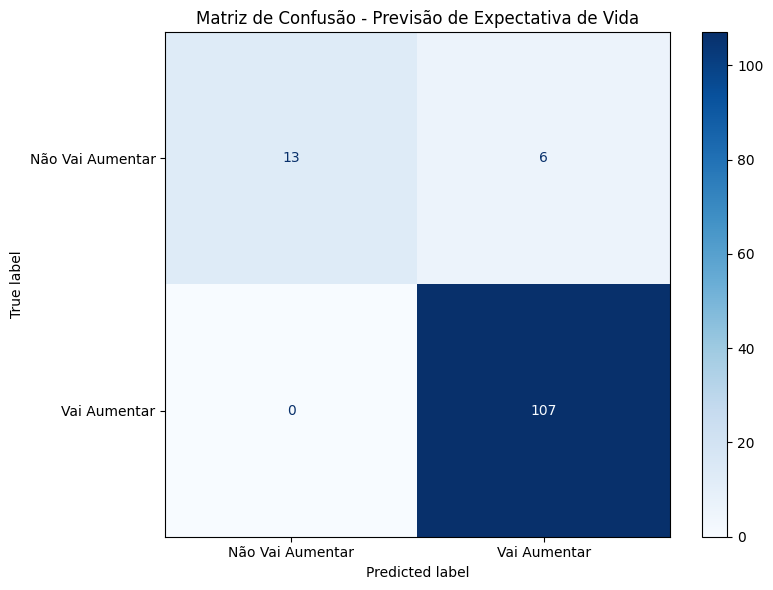

In [98]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calcula os valores da matriz de confusão
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Não Vai Aumentar', 'Vai Aumentar']
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap='Blues', ax=ax, values_format='d')

plt.title('Matriz de Confusão - Previsão de Expectativa de Vida')
plt.tight_layout()
plt.show()

### Análise dos Resultados do Modelo de Classificação

Avaliar o modelo de classificação treinado para prever se a expectativa de vida vai aumentar ou não traz informações importantes sobre o comportamento dos dados e o desempenho do algoritmo:

1. **Acurácia Geral de 95.24%**:
   O modelo apresenta um desempenho excelente, com mais de 95% de acertos globais no conjunto de teste. Contudo, precisamos analisar as métricas detalhadas devido ao grande desbalanceamento entre as classes.

2. **Análise das Métricas por Classe**
   * **Classe "Vai Aumentar" (Majoritária)**:
     * **Recall de 100%**: O modelo conseguiu identificar com sucesso todas as ocorrências em que a expectativa de vida de fato aumentou.
     * **Precisão de 95%**: Das vezes em que o modelo previu que haveria aumento, ele estava correto em 95% dos casos.
     * **F1-Score de 0.97**: Indica um desempenho excelente para esta classe majoritária.
   * **Classe "Não Vai Aumentar" (Minoritária)**:
     * **Precisão de 100%**: Todos os casos classificados pelo modelo como ausência de aumento da expectativa de vida pertenciam realmente a essa classe.
     * **Recall de 68%**: O modelo identificou corretamente 13 dos 19 casos reais em que a expectativa de vida não aumentou, deixando de identificar os 6 casos restantes, que foram classificados incorretamente como aumentos.
     * **F1-Score de 0.81**: Reflete a melhora em relação aos ajustes anteriores na capacidade do algoritmo em lidar com a classe minoritária.

3. **Informações a partir da Matriz de Confusão**:
   * **Falsos Positivos (6 casos)**: O modelo previu que a expectativa aumentaria, mas na verdade ela diminuiu ou estagnou. Em termos humanitários ou demográficos, este é o pior erro.
   * **Falsos Negativos (0 casos)**: O modelo nunca errou ao prever uma queda quando na verdade houve aumento.

### Conclusão
O modelo é extremamente confiável ao afirmar que a expectativa de vida não vai aumentar. No entanto, por conta do desbalanceamento natural dos dados, o classificador tende a ser ligeiramente otimista demais, deixando passar algumas quedas pontuais na expectativa de vida. Para mitigar isso em trabalhos futuros, técnicas de balanceamento de classes como SMOTE ou ajuste de pesos poderiam ser aplicadas.

# Random Forest para Regressão

Nesta etapa, realiza-se a criação e o treinamento do modelo Random Forest Regressor, um algoritmo de aprendizado supervisionado que combina múltiplas árvores de decisão para realizar tarefas de regressão. O modelo é treinado com os dados de treino para identificar padrões e relações entre as variáveis, visando prever se a expectativa de vida histórica dos países. Posteriormente, seu desempenho é avaliado com os dados de teste, verificando sua capacidade de generalização para dados não utilizados durante o treinamento.

In [99]:
# Instanciação e treinamento do modelo de regressão
reg = RandomForestRegressor(n_estimators=100, random_state=42)
reg.fit(X_train_reg, y_train_reg)

y_pred_reg = reg.predict(X_test_reg)

print(f"R² (Coeficiente de Determinação): {r2_score(y_test_reg, y_pred_reg):.4f}")
print(f"MAE (Erro Absoluto Médio): {mean_absolute_error(y_test_reg, y_pred_reg):.4f} anos")
print(f"MSE (Erro Quadrático Médio): {mean_squared_error(y_test_reg, y_pred_reg):.4f}")

R² (Coeficiente de Determinação): 0.9793
MAE (Erro Absoluto Médio): 0.7924 anos
MSE (Erro Quadrático Médio): 2.2065


### Avaliação do Modelo de Regressão

Nesta etapa, avaliamos o modelo de regressão utilizando o **Random Forest Regressor**, com o objetivo de prever a expectativa de vida histórica (`p_life_expect`) dos países a partir das demais características numéricas do dataset. As métricas obtidas atestam um desempenho preditivo ótimo:

* **R² (Coeficiente de Determinação) = 0.9793**: O modelo conseguiu capturar e explicar quase 98% da variância dos dados. O ajuste do modelo às predições foi extremamente fiel à realidade, indicando que as variáveis selecionadas (ano, fertilidade e expectativa de vida atual/futura) possuem forte correlação não-linear extraída com sucesso pelo algoritmo.
* **MAE (Erro Absoluto Médio) = 0.7924 anos**: A margem de erro média das predições do modelo é de apenas 0.79 anos (aproximadamente 9 meses e meio). Em um escopo de dados demográficos onde a expectativa de vida varia amplamente (de 23 a 80 anos), um desvio médio tão baixo é uma precisão notável.
* **MSE (Erro Quadrático Médio) = 2.2065**: Por elevar as diferenças ao quadrado, o MSE penaliza desvios muito grandes. Um MSE de 2.20 reflete uma Raiz do Erro Quadrático Médio (RMSE) em torno de 1.48 anos. A proximidade entre o MAE e o RMSE indica uma excelente consistência e ausência de grandes desvios de erro.

O algoritmo demonstra forte consistência sem sinais de *underfitting* ou *overfitting* prejudicial, validando a abordagem de remoção dos valores nulos da variável alvo antes do treinamento.